<!--
Copyright © 2026 The Trustees of Indiana University and contributors.
This work is licensed under the Creative Commons Attribution-NonCommercial 4.0 International License (CC BY-NC 4.0).
You may use, share, and adapt this work for non-commercial purposes, subject to the terms of the license and appropriate attribution.
See the LICENSE file in the root of this repository for the full license terms.
https://creativecommons.org/licenses/by-nc/4.0/
-->

## Folder placement

Current location: `analyses/calibration/quality_variance/`

## 1) Data used

Describe the empirical data source(s) in enough detail for a future reader to obtain or reproduce it.

- **Dataset name or source**: COVID-19 data from SUPSI
- **Time range**: `2021-03-01` to `2021-03-31`
- **Access / documentation link**: Data has been collected with Twitter API, NewsGuard has been used to get the ratings. Data can be requested by contacting [Gianluca Nogara](https://gi-ux.github.io/)
- **Raw files / tables used**: tweets_calibrated_cleaned.parquet contains id, user_id, created_at, urls
- **Preprocessing steps**: 
   1. Remove tweets without classifiable domains
   2. Obtain the score from NewsGuard
   3. Exclude satira and potentially misinterpretable data
   4. Calculate the average score for user
- **Notes / limitations**: Data has been collected using the old Twitter API


In [1]:
import pandas as pd
import ast
from urllib.parse import urlparse
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Loading data...")
base = ''
data_path = base + "tweets_calibrated_cleaned.parquet"
file_path = base + 'newsguard_ratings.csv'
df = pd.read_parquet(data_path, engine='fastparquet')
df.head()

Loading data...


,id,user_id,created_at,urls
0,1366438606429184001,2335424845,2021-03-01,"[{'url': 'https://t.co/W7vhUYudTp', 'expanded_..."
1,1366438599575687171,222207235,2021-03-01,"[{'url': 'https://t.co/sibepIOsHy', 'expanded_..."
2,1366438604990414849,825558208425062402,2021-03-01,"[{'url': 'https://t.co/wniKe1j6V7', 'expanded_..."
3,1366438605548314626,23444722,2021-03-01,"[{'url': 'https://t.co/1NMWWVgAri', 'expanded_..."
4,1366438606227709954,1076733241715900417,2021-03-01,"[{'url': 'https://t.co/5Qp907sJHv', 'expanded_..."


In [3]:
# Provide script used to prepare the data.
newsguard = pd.read_csv(file_path, lineterminator='\n', low_memory=False, encoding='utf-8')

# Remove satire from NewsGuard and obtain the list of domains from tweets
def clean_up(df, newsguard):
    newsguard = newsguard.rename(columns={'identifier': 'domain'})
    newsguard = newsguard[['domain', 'rank', 'score']]
    newsguard = newsguard[newsguard['rank']!= 'S']
    df['urls'] = df['urls'].apply(lambda x: ast.literal_eval(x)[0]['expanded_url'] if pd.notnull(x) else None)
    df['urls'] = df['urls'].apply(lambda x: urlparse(x).netloc.replace('www.', '') if pd.notnull(x) else None)
    df.rename(columns={'urls': 'domain'}, inplace=True)
    return df, newsguard
# merge datasets
def transform(df, newsguard):
    df_merge = pd.merge(df, newsguard[['domain', 'score']], on='domain', how='left')
    df_merge = df_merge[df_merge['score'].notna()]
    return df_merge

df, newsguard = clean_up(df, newsguard)
df_merge = transform(df, newsguard)
df_merge

,id,user_id,created_at,domain,score
4,1366438606227709954,1076733241715900417,2021-03-01,nationalgeographic.com,100.0
9,1366438594441736193,1462504146,2021-03-01,theguardian.com,100.0
11,1366438594974535683,940217378876674048,2021-03-01,pscp.tv,0.0
20,1366438608698286084,1066062101498740736,2021-03-01,washingtonpost.com,100.0
21,1366438608698286084,1066062101498740736,2021-03-01,washingtonpost.com,100.0
...,...,...,...,...,...
21993456,1377192669751939078,772914588568395780,2021-03-31,factcheck.org,100.0
21993459,1377192670699921409,1333883500924121092,2021-03-31,welt.de,82.0
21993460,1377192673396760578,1330667748,2021-03-31,newscientist.com,92.5
21993467,1377192681223294976,2699284032,2021-03-31,theguardian.com,100.0


## 2) New feature contribution

Explain what new feature this calibration adds and where it lives in the codebase.

- **Component**: `Message`
- **What it adds**: Function to generate the quality based on one parameter
- **Code location**: `libs/simsom/message.py`
- **Design rationale**: This approach is simple and flexible: with a single parameter, we can generate a realistic binomial distribution


## 2b) References & provenance

Make the calibration traceable to specific code and design. Complete one or more of items below.



## 3) Analysis / calibration method

Document how you transform the data into model parameters or behaviors.

- **Features extracted**: From the quality of the URLS shared by the users, we extract the distribution of the variance of quality. 
- **Estimation / fitting**: We observe that a simple gaussian with low noise fit.
- **Validation**: We followed insight from empirical data.

In [4]:
MIN_OBSERVATIONS = 3

user_counts = df_merge['user_id'].value_counts()
valid_users = user_counts[user_counts >= MIN_OBSERVATIONS].index
df_filtered = df_merge[df_merge['user_id'].isin(valid_users)]

print(f"Total users: {df_merge['user_id'].nunique()}")
print(f"Users with at least {MIN_OBSERVATIONS} observations: {len(valid_users)}\n")

user_variances = df_filtered.groupby('user_id')['score'].var().dropna()

mean_variance = user_variances.mean()
print(f"Mean variance of users: {mean_variance:.2f}\n")
user_stds = df_filtered.groupby('user_id')['score'].std().dropna()

mean_std = user_stds.mean()
print(f"Mean standard deviation of users: {mean_std:.2f}\n")

Total users: 878497
Users with at least 3 observations: 300901

Mean variance of users: 373.12

Mean standard deviation of users: 11.97



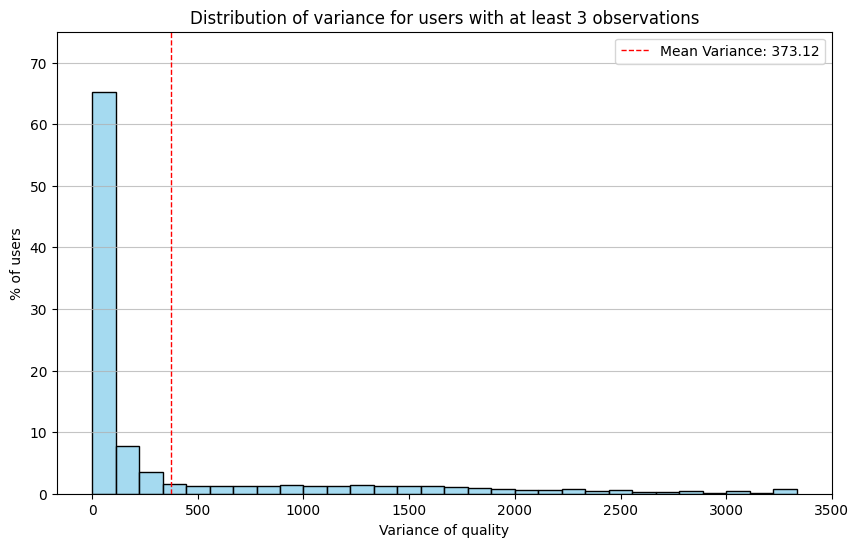

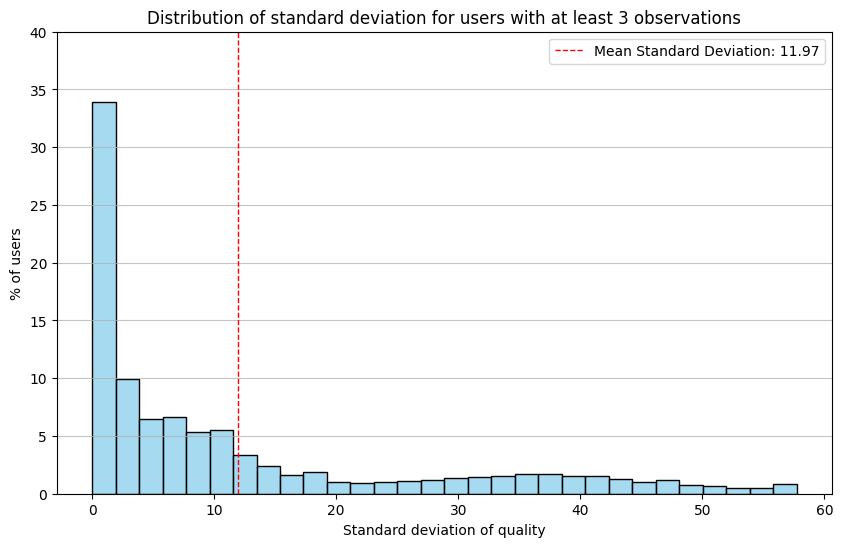

In [5]:
plt.figure(figsize=(10, 6))
plt.title('Distribution of variance for users with at least 3 observations')
plt.xlabel('Variance of quality')
plt.ylabel('% of users')
# set y axis
plt.ylim(0, 75)
# plot the distribution
sns.histplot(user_variances, bins=30, stat='percent', kde=False, color='skyblue', edgecolor='black')
# add vertical line for mean variance
plt.axvline(mean_variance, color='red', linestyle='dashed', linewidth=1, label=f'Mean Variance: {mean_variance:.2f}')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()  

plt.figure(figsize=(10, 6))
plt.title('Distribution of standard deviation for users with at least 3 observations')
plt.xlabel('Standard deviation of quality')
plt.ylabel('% of users')
# set y axis
plt.ylim(0, 40)
# plot the distribution
sns.histplot(user_stds, bins=30, stat='percent', kde=False, color='skyblue', edgecolor='black')
# add vertical line for mean standard deviation
plt.axvline(mean_std, color='red', linestyle='dashed', linewidth=1, label=f'Mean Standard Deviation: {mean_std:.2f}')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()

## 3b) Reproduction steps

Provide minimal steps so a new researcher can reproduce the analysis.

1. Ensure paths are correct
2. Run the notebook top-to-bottom to reproduce the plots anhd fitted params


## 4) Results

Summarize the outcome and attach key plots/tables. If large, don't upload to repo.

- **Outputs / artifacts**: Function to add gaussian noise
- **Where results are saved**: 
- **Key takeaways**: Each user has a gaussian noise for quality, based on the value of quality obtained by the function

## 5) Change log

Record updates so future changes are traceable.

- `2026-07-15`: Obtained the results
